# Checkpoint 2: cash-flow valuation and timing checks
**Prices: 6 November 2026. Review: 8 November 2026. USD.**

This companion to [the main portfolio notebook](round2_analysis.ipynb) works through three further checks: financing-consistent FCFF/FCFE valuation, market-implied growth, and returns with delayed or no rerating. It then repeats the portfolio tests at the agreed holdings.

The six stocks, target weights and entered share counts stay fixed. The lower-of-methods valuation is a sensitivity, not a new allocation. Run all cells to reproduce the calculations from the saved public inputs. The historical validation step refreshes CSV results in `results/valuation/`; it does not alter the Excel model or Overleaf report.

In [1]:
from pathlib import Path
import json, sys, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

def find_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for rel in ['research/round-2', '.']:
            root=base/rel
            if (root/'code/valuation.py').exists() and (root/'results/valuation/input_manifest.json').exists():
                return root.resolve()
    raise FileNotFoundError('Open this notebook with the complete repository data and code folders.')
ROOT=find_root()
sys.path.insert(0,str(ROOT/'code'))
from valuation import prepare_inputs, value_stocks, portfolio_research, fcff_value, finance_schedule, discount_rates, solve_root, ETFS, SAA, STOCKS, POLICY
OUT=ROOT/'results/valuation'
read=lambda f:json.loads((OUT/f).read_text())
pd.options.display.float_format=lambda x:f'{x:,.6f}'
pd.options.display.max_columns=16
print('Offline input root:',ROOT.name)
manifest=read('input_manifest.json')
assert all(hashlib.sha256((ROOT/f).read_bytes()).hexdigest()==h for f,h in manifest.items())
print('Archived input hashes verified:',len(manifest))

Offline input root: round-2
Archived input hashes verified: 44


## 1. Establish the requirements
The course uses the original six-ETF SAA benchmark, 3–6 long-only stocks, classroom alpha/residual-variance proportions and a 2–5% annual tracking error from 60 complete monthly USD returns. One-third in stocks is the class instruction reported by the team.

The proportional two-thirds ETF funding is our research choice. Daily 5% TE and 8% single-stock limits are additional preferences. Information ratio is the active-selection metric. A course IR is a model forecast; it is not a realized Sharpe ratio or guaranteed mark.

In [2]:
inputs,market=prepare_inputs()
prices,daily,monthly,excess=market
assert len(monthly.tail(60))==60
assert monthly.index[-1].strftime('%Y-%m')=='2026-10'
display(pd.DataFrame({'ETF':ETFS,'SAA':SAA,'Research funding target':SAA*2/3}))
print('Covariance window:',monthly.tail(60).index[0].date(),'to',monthly.index[-1].date())

,ETF,SAA,Research funding target
0,SPY,0.260800,0.173867
1,EEMV,0.096600,0.064400
2,DBC,0.269500,0.179667
3,SCHD,0.032800,0.021867
4,VGSH,0.050000,0.033333
5,STIP,0.290300,0.193533


Covariance window: 2021-11-30 to 2026-10-31


## 2. Reconcile NAV and preserve the entered holdings
The November 6 NAV is securities plus opening cash plus entitled distributions. Both VGSH and STIP distributions had been paid by this date. No challenge transaction fees or reserve are charged. The team added one SPY and one Adobe share after floor rounding.

These are the recorded entries. No replacement quantities are generated.

In [3]:
from decimal import Decimal
securities=Decimal('97014139.67'); opening_cash=Decimal('12.12')
vgsh=Decimal(86671)*Decimal('0.1889')
stip=Decimal(288630)*Decimal('0.292917')
nav=securities+opening_cash+vgsh+stip
assert nav==Decimal('97115068.575610')
old=read('portfolio.json')['old_implementation']
entered=pd.DataFrame(old['holdings'])
entered_value=sum(Decimal(str(h['price']))*h['target_shares'] for h in old['holdings'])
cash=nav-entered_value
assert cash==Decimal('116.045610')
print('NAV:',f'${nav:,.2f}','One-third stock budget:',f'${nav/3:,.2f}','Entered-book cash:',f'${cash:,.2f}')
display(entered[['ticker','price','target_shares']])

NAV: $97,115,068.58 One-third stock budget: $32,371,689.53 Entered-book cash: $116.05


,ticker,price,target_shares
0,SPY,735.290000,22964
1,EEMV,69.710000,89717
2,DBC,31.540000,553213
3,SCHD,35.170000,60380
4,VGSH,57.860000,55948
5,STIP,100.510000,186996
6,ADBE,239.300000,18865
7,KR,67.700000,116215
8,HRL,21.950000,305167
9,BMY,62.140000,99004


## 3. Correct sources before calculating value
Debt excludes operating lease liabilities because operating lease payments remain in CFO. Otherwise the same obligation is counted twice. Current cash/debt balances are never summed over four quarters. Share counts are the archived outstanding counts; they are distinct from diluted EPS averages.

The CFO method already contains working-capital changes, cash taxes, D&A and noncash adjustments. They must not be added again. SBC is charged once as an economic cost. This is an aggregate cash forecast, not a detailed revenue/margin/working-capital budget.

In [4]:
source_inputs=pd.DataFrame(inputs)
display(source_inputs[['ticker','statement_period','cfo','capex','sbc','normalization','net_interest','cash','debt','minority']])
display(source_inputs[['ticker','interest_basis','source']])

,ticker,statement_period,cfo,capex,sbc,normalization,net_interest,cash,debt,minority
0,ADBE,2026-08-28,"10,806.000000",214.000000,"2,071.000000",0.000000,-12.927600,"5,639.000000","6,363.000000",0.000000
1,KR,2026-08-15,"6,708.000000","4,324.000000",175.000000,0.000000,661.000000,"1,475.000000","16,997.000000",0.000000
2,HRL,2026-07-26,"1,091.658000",310.789000,25.508000,0.000000,52.562333,868.446000,"2,855.123000",0.000000
3,BMY,2026-09-30,"10,652.000000","1,366.000000",552.000000,0.000000,"1,025.784400","12,959.000000","42,877.000000",0.000000
4,XOM,2026-09-30,"70,589.000000","27,625.000000","1,040.000000","8,454.775560",279.794800,"12,153.000000","34,250.000000","6,731.000000"
5,HPQ,2026-07-31,"4,668.000000",787.000000,479.000000,957.130000,277.220400,"4,169.000000","9,160.000000",0.000000
6,FDS,2026-08-31,822.200000,114.720000,84.099000,0.000000,50.620000,265.332000,"1,370.022000",0.000000
7,INTU,2026-07-31,"8,838.000000",221.000000,"2,056.000000","1,279.000000",-92.480000,"7,200.000000","7,669.000000",0.000000
8,GILD,2026-09-30,"14,479.000000",699.000000,913.000000,"4,460.000000",699.449200,"6,437.000000","26,231.000000",0.000000


,ticker,interest_basis,source
0,ADBE,TTM provider interest less 4.84% yield on late...,https://www.sec.gov/Archives/edgar/data/796343...
1,KR,"Issuer rolling-four-quarter net interest, Tabl...",https://ir.kroger.com/news/news-details/2026/K...
2,HRL,TTM interest less annualized issuer nine-month...,https://www.hormelfoods.com/wp-content/uploads...
3,BMY,TTM provider interest less 4.84% yield on late...,https://www.bms.com/assets/bms/us/en-us/pdf/in...
4,XOM,TTM provider interest less 4.84% yield on late...,https://investor.exxonmobil.com/sec-filings/al...
5,HPQ,TTM provider interest less 4.84% yield on late...,https://www.hp.com/content/dam/sites/garage-pr...
6,FDS,Issuer FY26 interest expense 54.684 less inter...,https://investor.factset.com/static-files/ba92...
7,INTU,TTM provider interest less 4.84% yield on late...,https://investors.intuit.com/sec-filings/all-s...
8,GILD,TTM provider interest less 4.84% yield on late...,https://www.sec.gov/Archives/edgar/data/882095...


The main normalizations are: XOM maps the original normalized $10 EPS scenario to cash through the median historical CFO-minus-net-income bridge; HPQ uses guided FCF less the tariff-refund proxy and SBC; INTU excludes the FY26 deferred-tax addback in a no-repeat scenario; GILD returns to FY2025 CFO. These are analyst scenarios. Their cash occurred historically; it is not being called fictitious.

Cash-income proxies are disclosed where a comparable net-interest breakdown is unavailable. Borrowing spreads and normalized tax rates are assumptions, not observed bond yields or reported effective tax rates.

## 3a. Preserve the original fundamentals, peers and catalysts
The earlier annual comparisons and value-trap checks remain part of the checkpoint analysis. They compare each company's latest annual ratios with its prior observations and peer median. These are annual provider-basis comparisons, not the latest quarterly debt/cash used in the DCF. Undefined negative-equity ratios remain unavailable.

Peer multiples are the original archived calibration snapshot, not the final November 6 entry prices. Forward analyst EPS can use a different adjusted basis from issuer GAAP guidance; those bases are not interchangeable. The chosen P/E is a judgment, not an unadjusted average of heterogeneous peers.

In [5]:
annual=pd.read_csv(ROOT/'results/annual.csv')
quality=pd.read_csv(ROOT/'results/quality.csv')
quality['comparison_status']=quality.apply(lambda r:'Unavailable'if any(pd.isna(r[k])for k in ['latest','prior_mean','peer_median'])else 'Warning'if r['warning']else 'No dual warning',axis=1)
peers=pd.read_csv(ROOT/'results/peer_multiples.csv')
display(annual[annual.ticker.isin(STOCKS[:6])][['ticker','fiscal_end','TotalRevenue','NetIncome','OperatingCashFlow','CapitalExpenditure','TotalDebt','StockholdersEquity']])
display(quality[quality.ticker.isin(STOCKS[:6])][['ticker','metric','latest','prior_mean','peer_median','preferred','comparison_status']])
display(peers[peers.subject.isin(STOCKS[:6])])
for t in STOCKS[:6]:
    a=POLICY['valuation'][t]
    display(Markdown('**'+t+' original EPS/P-E case:** '+a['basis']+' Fair multiple: '+str(a['pe'])+'x. '+a.get('reason',a.get('pe_reason',''))+' **Catalyst:** '+a['catalyst']))

,ticker,fiscal_end,TotalRevenue,NetIncome,OperatingCashFlow,CapitalExpenditure,TotalDebt,StockholdersEquity
8,ADBE,2022-11-30,"17,606,000,000.000000","4,756,000,000.000000","7,838,000,000.000000","-442,000,000.000000","4,633,000,000.000000","14,051,000,000.000000"
9,ADBE,2023-11-30,"19,409,000,000.000000","5,428,000,000.000000","7,302,000,000.000000","-360,000,000.000000","4,080,000,000.000000","16,518,000,000.000000"
10,ADBE,2024-11-30,"21,505,000,000.000000","5,560,000,000.000000","8,056,000,000.000000","-183,000,000.000000","6,056,000,000.000000","14,105,000,000.000000"
11,ADBE,2025-11-30,"23,769,000,000.000000","7,130,000,000.000000","10,031,000,000.000000","-179,000,000.000000","6,648,000,000.000000","11,623,000,000.000000"
16,BMY,2022-12-31,"46,159,000,000.000000","6,327,000,000.000000","13,066,000,000.000000","-1,118,000,000.000000","40,717,000,000.000000","31,061,000,000.000000"
17,BMY,2023-12-31,"45,006,000,000.000000","8,025,000,000.000000","13,860,000,000.000000","-1,209,000,000.000000","41,464,000,000.000000","29,430,000,000.000000"
18,BMY,2024-12-31,"48,300,000,000.000000","-8,948,000,000.000000","15,190,000,000.000000","-1,248,000,000.000000","51,200,000,000.000000","16,335,000,000.000000"
19,BMY,2025-12-31,"48,195,000,000.000000","7,054,000,000.000000","14,156,000,000.000000","-1,311,000,000.000000","47,139,000,000.000000","18,473,000,000.000000"
56,HPQ,2022-10-31,"62,910,000,000.000000","3,132,000,000.000000","4,463,000,000.000000","-765,000,000.000000","12,294,000,000.000000","-3,025,000,000.000000"
57,HPQ,2023-10-31,"53,718,000,000.000000","3,263,000,000.000000","3,571,000,000.000000","-593,000,000.000000","10,739,000,000.000000","-1,069,000,000.000000"


,ticker,metric,latest,prior_mean,peer_median,preferred,comparison_status
0,ADBE,ROE,0.613439,0.353760,0.240417,Higher,No dual warning
1,ADBE,FCF_margin,0.414489,0.381285,0.346827,Higher,No dual warning
2,ADBE,Revenue_growth,0.105278,0.105200,0.138973,Higher,No dual warning
3,ADBE,Gross_margin,0.892675,0.882033,0.776761,Higher,No dual warning
4,ADBE,Debt_equity,0.571969,0.335361,0.443397,Lower,Warning
5,ADBE,Payout_FCF,1.145047,0.908698,0.884587,Lower,Warning
6,KR,ROE,0.171419,0.243813,0.219772,Higher,Warning
7,KR,FCF_margin,0.023408,0.013626,0.020925,Higher,No dual warning
8,KR,Revenue_growth,0.003528,-0.003711,0.034601,Higher,No dual warning
9,KR,Gross_margin,0.233010,0.221251,0.271805,Higher,No dual warning


,subject,ticker,price,annual_eps,annual_date,annual_pe,next_eps,next_pe,current_eps
0,ADBE,ADBE,246.440000,16.700000,2025-11-30,14.756886,27.429000,8.984652,24.477910
1,ADBE,CRM,222.410000,7.800000,2026-01-31,28.514103,16.015230,13.887406,16.754840
2,ADBE,INTU,354.840000,16.460000,2026-07-31,21.557716,26.943820,13.169624,23.810460
3,ADBE,ORCL,115.160000,5.830000,2026-05-31,19.753002,11.054420,10.417552,8.141850
4,KR,KR,69.430000,1.540000,2026-01-31,45.084416,5.473410,12.684962,5.188170
5,KR,ACI,13.240000,0.400000,2026-02-28,33.100000,1.653830,8.005659,1.736480
6,KR,WMT,127.720000,2.730000,2026-01-31,46.783883,3.226450,39.585304,2.886560
7,KR,TGT,157.950000,8.130000,2026-01-31,19.428044,9.545250,16.547497,10.515410
8,HRL,HRL,22.600000,0.870000,2025-10-31,25.977011,1.566790,14.424397,1.483590
9,HRL,TSN,60.110000,1.330000,2025-09-30,45.195489,3.858370,15.579118,3.554120


**ADBE original EPS/P-E case:** FY26 company GAAP EPS midpoint18.12-18.17; SBC included. Fair multiple: 16x. 16x discounts current software peer multiples and AI/renewal uncertainty; cash value remains above price. **Catalyst:** December9 results, confirmed issuer calendar.

**KR original EPS/P-E case:** FY26 company adjusted EPS midpoint5.10-5.30, reaffirmed October20; past fulfilment impairment excluded, not called growth. Fair multiple: 15x. 15x below heterogeneous retail peer forward median; cash cross-check supports roughly78; debt/capital allocation remain warnings. **Catalyst:** December3 results, confirmed issuer announcement.

**HRL original EPS/P-E case:** FY26 adjusted guidance1.45-1.51 midpoint; GAAP1.06-1.12 affected by divestiture/impairment/legal items, not organic earnings growth. Fair multiple: 17x. 17x is a judgemental premium to leveraged mixed food peers for brands, Foodservice execution and historically stronger balance sheet. Acquisition increases leverage; dividend coverage is only modest. Cash and modest-growth DDM cross-checks support value around/above25. **Catalyst:** December3 FY26 results and first FY27 outlook, confirmed issuer calendar; Brakebush integration/funding details.

**BMY original EPS/P-E case:** FY26 company nonGAAP6.35-6.55 midpoint; retains0.60 acquired-IPRD/licensing impact rather than adding it back. Fair multiple: 11x. 11x discounts pharma peers for patent/generic erosion and acquisition risk. TTM owner-cash proxy with no growth supports value near69, close to the earnings value70.95; downside cash-decline cases required. **Catalyst:** Issuer October29 presentation expects remaining2026 Sotyktu SLE and other clinical readouts; conference data at ASH requires primary-program confirmation. No approval probability assumed.

**XOM original EPS/P-E case:** Judgemental normalized EPS of USD 10.00, below Yahoo FY2027 consensus USD 12.01328 and close to reported trailing EPS USD 9.72. It deliberately does not annualize Q3 adjusted EPS of USD 4.23. This is an analyst scenario, not company guidance. Fair multiple: 18x. 18x is a judgemental premium for an integrated major with low-cost production growth. Compare integrated Chevron and upstream COP/EOG cautiously; cyclically inflated EPS can make all oil P/Es misleading. **Catalyst:** Management expects Uaru startup in Q4 and a press release with 2027 planning metrics later in Q4. There is explicitly no formal December investor-day event. Expected before year-end, with a real risk of slipping beyond the Dec 27 challenge cutoff.

**HPQ original EPS/P-E case:** FY2026 company GAAP EPS midpoint 2.57 less 0.19 of tariff refunds = 2.38. Do not capitalize the refund as recurring earnings. Fair multiple: 13.5x. 13.5x normalized GAAP earnings is judgemental. A separate same-provider adjusted-forward peer calculation gives about USD 32.98: HPQ FY2027 consensus EPS 3.15375 times the 10.459x median of Dell, HPE and Cisco. HPE's latest annual GAAP loss makes its historical GAAP P/E unusable; it is not treated as a positive comparison. **Catalyst:** FY2026 results and FY2027 guidance; PC pricing/memory costs, print supplies and cash generation.

## 4. Match cash flow, financing and discount rates

\[FCFF_0=CFO-normalization-capex-SBC+net\ interest(1-tax).\]

Cash investment income is removed in the net-interest bridge before cash is added separately. The equity CAPM input uses the same last 60 monthly excess returns as before. Cash is stripped from market equity to obtain the operating equity hurdle. Debt and minority equity are included in the operating capital structure. Reported debt carrying amounts proxy for market debt; individual bonds are not repriced.

\[WACC=k_{operating}(1-d)+k_D(1-tax)d.\]

Forecast FCFF grows at the stated first-stage rate for five years, then at the terminal rate. Terminal growth must be below WACC. FCFF discounted at WACC gives enterprise value; subtract debt and minority interests, then add cash to reach common equity.

In [6]:
valuations,schedules,convergence,sensitivities=value_stocks(inputs)
v=pd.DataFrame(valuations).set_index('ticker')
display(v[['k','debt_rate','dcf_ke_op','dcf_leverage','dcf_wacc','dcf_fcff0','growth','terminal_growth','dcf_value','multiple_value']])
# Independently verify Adobe's five-year cash discounting and equity bridge.
a=inputs[0];r=discount_rates(a)
f0=a['cfo']-a['normalization']-a['capex']-a['sbc']+a['net_interest']*(1-a['tax'])
flows=np.array([f0*(1+a['growth'])**j for j in range(1,6)])
pv=(flows/(1+r['wacc'])**np.arange(1,6)).sum()
tv=flows[-1]*(1+a['terminal_growth'])/(r['wacc']-a['terminal_growth'])
independent_value=(pv+tv/(1+r['wacc'])**5-a['debt']+a['cash']-a['minority'])/a['shares']
np.testing.assert_allclose(independent_value,v.loc['ADBE','dcf_value'])
print('Independent Adobe value:',independent_value)

,k,debt_rate,dcf_ke_op,dcf_leverage,dcf_wacc,dcf_fcff0,growth,terminal_growth,dcf_value,multiple_value
ticker,,,,,,,,,,
ADBE,0.131872,0.053400,0.137252,0.067793,0.130807,"8,510.787196",0.080000,0.030000,271.142181,290.320000
KR,0.070472,0.058400,0.071317,0.306225,0.063070,"2,711.360000",0.030000,0.020000,87.451431,78.000000
HRL,0.065182,0.058400,0.066482,0.202968,0.061996,795.308373,0.020000,0.020000,31.488280,25.160000
BMY,0.061356,0.058400,0.062828,0.273211,0.058268,"9,544.369676",0.000000,0.000000,65.498302,70.950000
XOM,0.058894,0.053400,0.059086,0.048551,0.058265,"33,690.262332",0.020000,0.020000,213.084181,180.000000
HPQ,0.120618,0.063400,0.134625,0.298800,0.109364,"2,663.874116",0.040000,0.030000,34.444922,32.130000
FDS,0.090666,0.058400,0.091659,0.108137,0.086736,663.370800,0.055000,0.030000,349.220001,370.875000
INTU,0.103661,0.058400,0.108394,0.083604,0.103189,"5,208.940800",0.080000,0.030000,336.398314,404.800000
GILD,0.069526,0.058400,0.070204,0.115660,0.067421,"8,959.564868",0.040000,0.025000,170.712242,177.100000


Independent Adobe value: 271.14218072679745


## 5. Reconcile cash value with the earnings method
Keep the original normalized EPS/P-E values as the selection record. Compare them with independent cash values. The lower-of-methods **audit value** is an extra conservative scenario, not a replacement target. Its reduction of future FCFF is displayed separately, so the FCFF, FCFE and convergence schedules share a consistent audit value without rewriting historical inputs or recorded holdings.

In [7]:
display(v[['price','multiple_value','dcf_value','decision_value','cash_haircut','gap','dcf_terminal_share']])
assert np.allclose(v.decision_value,np.minimum(v.dcf_value,v.multiple_value))
assert (v.cash_haircut<=1+1e-12).all()
assert np.allclose(v.fcfe_value,v.decision_value)
display(Markdown('**Company-specific reasoning**'))
for a in inputs: display(Markdown('**'+a['ticker']+'** — '+a['rationale']))

,price,multiple_value,dcf_value,decision_value,cash_haircut,gap,dcf_terminal_share
ticker,,,,,,,
ADBE,239.300000,290.320000,271.142181,271.142181,1.000000,0.133064,0.650358
KR,67.700000,78.000000,87.451431,78.000000,0.916899,0.152142,0.816243
HRL,21.950000,25.160000,31.488280,25.160000,0.819697,0.146241,0.817308
BMY,62.140000,70.950000,65.498302,65.498302,1.000000,0.054044,0.753394
XOM,165.870000,180.000000,213.084181,180.000000,0.849721,0.085187,0.831817
HPQ,28.460000,32.130000,34.444922,32.130000,0.942097,0.128953,0.694348
FDS,327.890000,370.875000,349.220001,349.220001,1.000000,0.065052,0.773698
INTU,341.500000,404.800000,336.398314,336.398314,1.000000,-0.014939,0.729462
GILD,166.890000,177.100000,170.712242,170.712242,1.000000,0.022903,0.820928


**Company-specific reasoning**

**ADBE** — 8% cash growth is below latest 13% revenue growth. SBC remains an economic expense. Competitive pressure from AI and REA/Artcraft is tested through lower cash and growth, rather than asserted customer losses. December 9 earnings are after the next rebalance.

**KR** — 3% cash growth assumes modest sales, mix and efficiency progress, not a repeat of buyback-driven EPS growth. Correct debt is 16,997, excluding 7,161 of operating leases already expensed in CFO. Thin margins and its 2.3-2.5x net-debt/EBITDA target make financing important. December 3 earnings are after the next rebalance.

**HRL** — 2% cash growth follows the low end of organic sales guidance, with no speculative acquisition earnings. Brakebush is 1,055 and expected to close in FY27 Q1. Base deal NPV is zero: acquired assets equal consideration, not a free asset or a deduction of the purchase price twice. Financing and value destruction are separate stresses. December 3 outlook is after the next rebalance.

**BMY** — Preserve the original flat-cash base assumption: pipeline delivery and cost savings offset legacy erosion in aggregate. This is an analyst scenario, not company guidance. Test 1%, 2% and 5% annual cash declines separately, rather than quietly replace the base case. The Q3 release reports Growth Portfolio revenue growth of 12%, but that does not prove future patent losses will be offset. Remaining-2026 readouts are uncertain and binary.

**XOM** — Keep business conditions consistent with the original normalized EPS scenario of 10: normalized common earnings are EPS times current shares; add the median 2023-2025 CFO-minus-common-net-income bridge of 21,342 to estimate normalized consolidated CFO. This bridge includes D&A, working capital, taxes and minority effects; it is not all depreciation. Retain TTM PP&E spending and charge 1,040 of annualized 9M stock awards. Subtract 6,731 NCI at book value as a market-value proxy. A lower-cycle historical-CFO case is a separate stress, not an unexplained base change.

**HPQ** — Use guided 3,100 FCF less 176.13 tariff-refund cash proxy and 479 SBC. 4% initial growth and 3% terminal growth need PC cash conversion and printing stabilization. The guide is levered FCF, so interest is unlevered once. November 24 earnings are a timely test.

**FDS** — Alternative reviewed: 5.5% first-stage cash growth is aligned with FY27 5-6.5% ASV guidance; 3% terminal growth assumes mature nominal growth. Do not use the old 7% cash growth. Fiscal 2026 CFO, capex, SBC and debt are verified to the release. November 10 Investor Day is timely. AI pricing competition and compensation accrual reversal remain risks.

**INTU** — Alternative reviewed: remove 1,279 of FY26 deferred-tax addback from recurring CFO as a conservative no-repeat scenario. This is a normalization assumption, not a claim that past cash was fictitious. Keep SBC charged, remove operating leases from debt, and show an unadjusted-tax alternative. November 19 earnings are timely, but the cash margin is insufficient in the normalized case.

**GILD** — Alternative reviewed: revert CFO to FY2025 10,019 rather than extrapolate TTM 14,479, while retaining current capex and SBC. Acquisition cash is already reflected in cash/debt; it is not added back or charged twice. No future deal benefit is forecast. 4% cash growth and 2.5% terminal growth require continued product delivery. December ASH/FDA events are binary and do not receive assumed approval probabilities.

## 6. Check FCFE against FCFF under the same debt policy

The modeled policy keeps debt at a constant fraction of forecast operating firm value. This is an explicit analytical assumption, not a statement of management's financing plan.

\[FCFE_t=FCFF_t-k_D D_{t-1}(1-tax)+(D_t-D_{t-1}).\]

The initial difference between model target debt and reported debt is retained in cash. Discount FCFE and the terminal equity claim at the operating equity rate, include that initial financing bridge and cash, then subtract the minority claim. It must reproduce the adopted FCFF common-equity value. Unrelated debt policies must not be forced to agree.

In [8]:
sch=pd.DataFrame(schedules)
display(sch[sch.ticker.isin(['ADBE','KR','HRL'])][['ticker','year','fcff','debt_begin','interest','net_borrowing','fcfe','debt_end','equity_end']].head(15))
display(v[['decision_value','fcfe_value']].assign(difference=v.decision_value-v.fcfe_value))
assert np.max(np.abs(v.decision_value-v.fcfe_value))<1e-8

,ticker,year,fcff,debt_begin,interest,net_borrowing,fcfe,debt_end,equity_end
0,ADBE,1,"9,191.650172","7,203.154279",384.648439,319.096387,"9,206.874292","7,522.250666","103,437.224070"
1,ADBE,2,"9,926.982185","7,522.250666",401.688186,310.986268,"9,920.634787","7,833.236935","107,713.544783"
2,ADBE,3,"10,721.140760","7,833.236935",418.294852,297.827273,"10,688.515100","8,131.064207","111,808.918324"
3,ADBE,4,"11,578.832021","8,131.064207",434.198829,278.639930,"11,514.454876","8,409.704137","115,640.449886"
4,ADBE,5,"12,505.138583","8,409.704137",449.078201,252.291124,"12,402.657928","8,661.995261","119,109.663383"
5,ADBE,6,"12,880.292740","8,661.995261",462.550547,259.859858,"12,774.737666","8,921.855119","122,682.953285"
6,ADBE,7,"13,266.701522","8,921.855119",476.427063,267.655654,"13,157.979796","9,189.510773","126,363.441883"
7,ADBE,8,"13,664.702568","9,189.510773",490.719875,275.685323,"13,552.719190","9,465.196096","130,154.345140"
8,ADBE,9,"14,074.643645","9,465.196096",505.441472,283.955883,"13,959.300766","9,749.151979","134,058.975494"
9,ADBE,10,"14,496.882955","9,749.151979",520.604716,292.474559,"14,378.079788","10,041.626538","138,080.744759"


,decision_value,fcfe_value,difference
ticker,,,
ADBE,271.142181,271.142181,-0.000000
KR,78.000000,78.000000,0.000000
HRL,25.160000,25.160000,0.000000
BMY,65.498302,65.498302,0.000000
XOM,180.000000,180.000000,-0.000000
HPQ,32.130000,32.130000,0.000000
FDS,349.220001,349.220001,-0.000000
INTU,336.398314,336.398314,0.000000
GILD,170.712242,170.712242,0.000000


## 7. Stress financing and shareholder distributions
The FCFE/FCFF identity is not proof of debt safety. Test no-extra-borrowing cash capacity separately for Kroger and Hormel. A refinancing stress resets all debt to the model rate. Brakebush receives no speculative operating benefit in these funding tests; they are deliberately stricter than a zero-NPV acquired-asset valuation.

In [9]:
funding=pd.DataFrame(read('funding_checks.json'))
display(funding[['ticker','scenario','debt','fcfe_no_net_borrowing','annual_dividends','dividend_cover','after_dividend_cash','annualized_or_ttm_buybacks']])

,ticker,scenario,debt,fcfe_no_net_borrowing,annual_dividends,dividend_cover,after_dividend_cash,annualized_or_ttm_buybacks
0,KR,"Existing coupons, no extra borrowing","16,997.000000","2,209.000000",921.318372,2.397651,"1,287.681628","3,767.000000"
1,KR,Refinance debt at model borrowing cost,"16,997.000000","1,956.965152",921.318372,2.124092,"1,035.646780","3,767.000000"
2,HRL,"Existing coupons, no extra borrowing","2,855.123000",755.361000,643.910436,1.173084,111.450564,0.000000
3,HRL,Refinance debt at model borrowing cost,"2,855.123000",688.515821,643.910436,1.069273,44.605385,0.000000
4,HRL,"Brakebush fully debt funded, existing coupons","3,910.123000",708.535880,643.910436,1.100364,64.625444,0.000000
5,HRL,Brakebush debt funded plus full refinancing,"3,910.123000",641.690701,643.910436,0.996553,-2.219735,0.000000


## 8. Reverse the model: what does the market price require?
Solve the first-stage cash growth that makes adopted cash value equal the November 6 price. Separately solve the duration of that first stage while holding growth and the other inputs fixed. Equal first/terminal growth makes duration unidentified. A missing root between 0 and 50 years is reported, not replaced with zero.

Duration describes the first-stage growth or decline assumption. These are conditional market-implied assumptions, not forecasts extracted from the stock price.

In [10]:
display(v[['growth','implied_growth','years','implied_duration','implied_duration_note','break_even_cash_scale']])
for a in inputs:
    g=v.loc[a['ticker'],'implied_growth']
    if pd.notna(g):
        check=fcff_value(a,growth=g,cash_scale=v.loc[a['ticker'],'cash_haircut'])['value']
        np.testing.assert_allclose(check,a['price'],atol=1e-7)
print('All available implied-growth roots reprice to market.')

,growth,implied_growth,years,implied_duration,implied_duration_note,break_even_cash_scale
ticker,,,,,,
ADBE,0.080000,0.048892,5,1.659339,"Years of the first-stage growth or decline, ho...",0.883363
KR,0.030000,0.007021,5,NaN,No duration solution between 0 and 50 years un...,0.901230
HRL,0.020000,-0.005862,5,NaN,Not identifiable: first and terminal growth ar...,0.888425
BMY,0.000000,-0.009526,5,NaN,Not identifiable: first and terminal growth ar...,0.958092
XOM,0.020000,0.002892,5,NaN,Not identifiable: first and terminal growth ar...,0.924466
HPQ,0.040000,0.015668,5,NaN,No duration solution between 0 and 50 years un...,0.902561
FDS,0.055000,0.041640,5,2.180184,"Years of the first-stage growth or decline, ho...",0.943948
INTU,0.080000,0.083641,5,5.423459,"Years of the first-stage growth or decline, ho...",1.015087
GILD,0.040000,0.035364,5,3.353385,"Years of the first-stage growth or decline, ho...",0.979524


All available implied-growth roots reprice to market.


## 9. Model delayed convergence and a discount that never closes
Pay the current annualized dividend, growing at the specified rate. Assume no future buybacks; retain remaining FCFE in cash at an after-tax Treasury yield and keep shares fixed. Sell at future modeled common-equity value after 1, 3, 5 or 10 years.

The never-convergence case preserves the initial proportional market discount on the future fair price. Dividends are actually paid in the scenario; available cash is not mislabeled a dividend. For non-dividend Adobe, the return comes from the terminal sale. The no-buyback/cash-retention policy is a scenario, not a forecast of management policy.

Show both IRR minus the initial CAPM hurdle and the IRR premium relative to buying at fair value under the same cash-retention policy. The latter separates the valuation gap from the changing risk of accumulating cash.

,ticker,years,full_convergence_irr,no_convergence_irr,initial_k,full_minus_k,never_minus_k,fair_purchase_irr,valuation_return_premium
0,ADBE,1,0.281691,0.131173,0.131872,0.149819,-0.000700,0.131173,0.150518
1,ADBE,3,0.172103,0.124297,0.131872,0.040231,-0.007575,0.124297,0.047806
2,ADBE,5,0.146636,0.118343,0.131872,0.014764,-0.013530,0.118343,0.028294
3,ADBE,10,0.120339,0.106430,0.131872,-0.011533,-0.025442,0.106430,0.013909
4,KR,1,0.231427,0.071919,0.070472,0.160955,0.001447,0.068815,0.162611
5,KR,3,0.120691,0.071032,0.070472,0.050220,0.000560,0.068009,0.052683
6,KR,5,0.099131,0.070185,0.070472,0.028659,-0.000287,0.067235,0.031896
7,KR,10,0.081987,0.068235,0.070472,0.011515,-0.002237,0.065448,0.016539
8,HRL,1,0.219429,0.070786,0.065182,0.154247,0.005605,0.063850,0.155579
9,HRL,3,0.115891,0.070903,0.065182,0.050709,0.005721,0.063943,0.051948


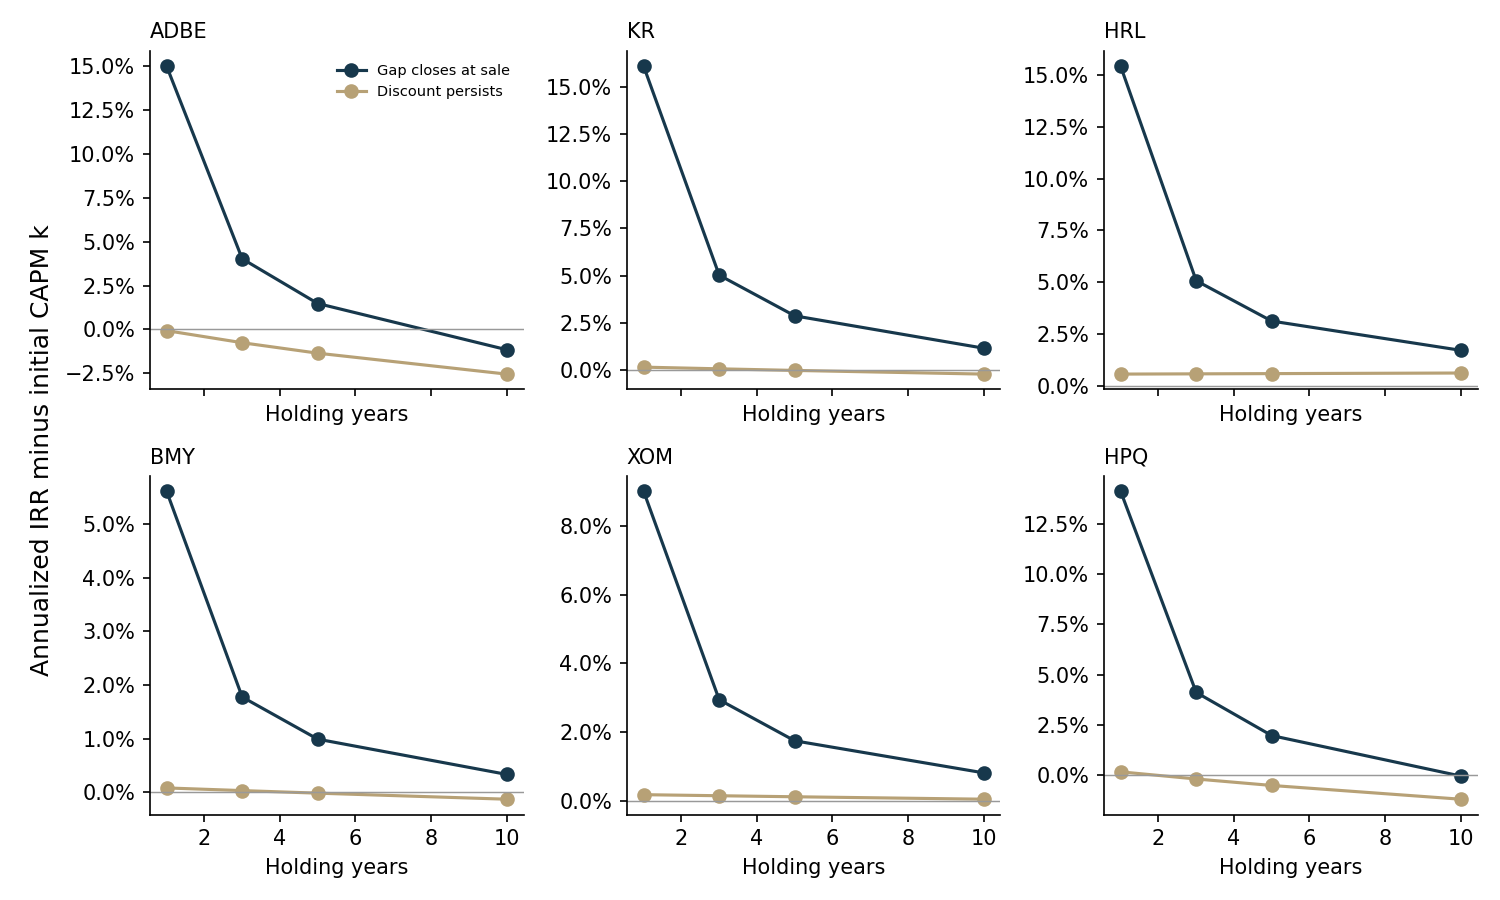

In [11]:
c=pd.DataFrame(convergence)
display(c[c.ticker.isin(STOCKS[:6])][['ticker','years','full_convergence_irr','no_convergence_irr','initial_k','full_minus_k','never_minus_k','fair_purchase_irr','valuation_return_premium']])
assert (c.min_retained_cash>=0).all()
display(Image(filename=str(OUT/'figures/convergence.png')))

## 10. Check cash-flow and discount-rate sensitivity
The same cash model is rerun for lower cash, higher equity/borrowing costs, lower terminal growth and zero growth. HRL acquisition value-loss scenarios, flat-cash BMY and repeating-tax-benefit INTU are explicitly separate cases. They are not probabilities. The high terminal-value share makes discount rates and cash persistence material.

In [12]:
sensitivity=pd.DataFrame(sensitivities)
display(sensitivity.pivot(index='ticker',columns='scenario',values='decision_value').round(2))
display(v[['price','decision_value','dcf_terminal_share','break_even_cash_scale']])

scenario,Base,Brakebush 100% consideration destroyed,Brakebush 25% consideration destroyed,Brakebush 50% consideration destroyed,Cash minus 10%,Cash minus 20%,Cost equity plus 1pp,Cost equity plus 2pp,Debt cost plus 2pp,Lower-cycle median historical CFO,Patent erosion: cash declines 1% for 5 years,Patent erosion: cash declines 2% for 5 years,Patent erosion: cash declines 5% for 5 years,Repeat FY26 deferred-tax cash benefit,Terminal growth minus 1pp,Zero growth
ticker,,,,,,,,,,,,,,,,
ADBE,271.140000,NaN,NaN,NaN,243.840000,216.540000,245.930000,224.900000,268.180000,NaN,NaN,NaN,NaN,NaN,253.550000,165.310000
BMY,65.500000,NaN,NaN,NaN,57.480000,49.470000,55.720000,48.080000,59.970000,NaN,61.980000,58.590000,49.170000,NaN,56.140000,65.500000
FDS,349.220000,NaN,NaN,NaN,311.170000,273.110000,295.940000,255.650000,337.980000,NaN,NaN,NaN,NaN,NaN,302.670000,185.530000
GILD,170.710000,NaN,NaN,NaN,152.050000,133.380000,137.500000,114.280000,162.960000,NaN,NaN,NaN,NaN,NaN,140.270000,91.180000
HPQ,32.130000,NaN,NaN,NaN,30.450000,26.450000,30.610000,27.440000,32.130000,NaN,NaN,NaN,NaN,NaN,31.100000,21.480000
HRL,25.160000,25.160000,25.160000,25.160000,25.160000,24.470000,25.160000,21.300000,25.160000,NaN,NaN,NaN,NaN,NaN,25.160000,19.700000
INTU,336.400000,NaN,NaN,NaN,302.580000,268.770000,294.960000,262.410000,330.260000,NaN,NaN,NaN,NaN,404.800000,304.640000,187.140000
KR,78.000000,NaN,NaN,NaN,76.080000,64.700000,71.100000,58.850000,76.320000,NaN,NaN,NaN,NaN,NaN,69.220000,46.510000
XOM,180.000000,NaN,NaN,NaN,180.000000,169.050000,168.610000,139.080000,180.000000,166.610000,NaN,NaN,NaN,NaN,173.720000,134.680000


,price,decision_value,dcf_terminal_share,break_even_cash_scale
ticker,,,,
ADBE,239.300000,271.142181,0.650358,0.883363
KR,67.700000,78.000000,0.816243,0.901230
HRL,21.950000,25.160000,0.817308,0.888425
BMY,62.140000,65.498302,0.753394,0.958092
XOM,165.870000,180.000000,0.831817,0.924466
HPQ,28.460000,32.130000,0.694348,0.902561
FDS,327.890000,349.220001,0.773698,0.943948
INTU,341.500000,336.398314,0.729462,1.015087
GILD,166.890000,170.712242,0.820928,0.979524


## 11. Compare alphas while holding the portfolio fixed
The selection record used $\alpha=(1+k)(V/P-1)$ with a common 50% comparison scale and alpha/residual-variance proportions. That construction and all entered quantities remain unchanged.

The lower-of-methods cash-audit alpha is a sensitivity result. Do not renormalize weights from it, call it a new allocation, or treat a stressed negative alpha as proof of new adverse company news. The physical convergence return is a separate calculation; a common 50% alpha scale is not a closure probability.

In [13]:
research,_=portfolio_research(valuations,market)
chosen=research['chosen']
original_alpha={r['ticker']:r['alpha']for r in research['original_rows']}
display(v[['multiple_value','decision_value','alpha_full','alpha','residual_variance']].assign(original_alpha=pd.Series(original_alpha)))
display(pd.DataFrame(research['implementation'])[['ticker','weight','target_shares','entered_weight']])
weights=np.array(chosen['weights'])
assert abs(weights[6:].sum()-1/3)<1e-12
assert np.count_nonzero(weights[6:])==6
assert chosen['stocks']==['ADBE','KR','HRL','BMY','XOM','HPQ']
assert research['old_implementation']['holdings']==old['holdings']
print('Original targets and entered quantities preserved. No automatic resizing.')

,multiple_value,decision_value,alpha_full,alpha,residual_variance,original_alpha
ticker,,,,,,
ADBE,290.320000,271.142181,0.150611,0.075306,0.121203,0.120661
KR,78.000000,78.000000,0.162864,0.081432,0.046933,0.081432
HRL,25.160000,25.160000,0.155774,0.077887,0.052727,0.077887
BMY,70.950000,65.498302,0.057360,0.028680,0.055456,0.075238
XOM,180.000000,180.000000,0.090204,0.045102,0.058157,0.045102
HPQ,32.130000,32.130000,0.144507,0.072254,0.090452,0.072254
FDS,370.875000,349.220001,0.070950,0.035475,0.070778,NaN
INTU,404.800000,336.398314,-0.016488,-0.008244,0.122336,NaN
GILD,177.100000,170.712242,0.024495,0.012248,0.054441,NaN


,ticker,weight,target_shares,entered_weight
0,SPY,0.173867,22964,0.173868
1,EEMV,0.064400,89717,0.064400
2,DBC,0.179667,553213,0.179667
3,SCHD,0.021867,60380,0.021866
4,VGSH,0.033333,55948,0.033333
5,STIP,0.193533,186996,0.193533
6,ADBE,0.046484,18865,0.046485
7,KR,0.081015,116215,0.081015
8,HRL,0.068974,305167,0.068974
9,BMY,0.063349,99004,0.063349


Original targets and entered quantities preserved. No automatic resizing.


## 12. Test current risk using four covariance estimates
The official check uses 60 complete monthly returns. Daily 252, daily 63 and EWMA estimates expose current risk that this monthly calibration can miss. These are separate risk estimates; passing the monthly band does not make the daily preference pass.

In [14]:
comparisons=research['comparisons']
risk=pd.DataFrame([{'Portfolio':r['name'],'Monthly60':r['risk']['Monthly60'],'Daily252':r['risk']['Daily252'],'Daily63':r['risk']['Daily63'],'EWMA252':r['risk']['EWMA252'],'Max stock':r['max_stock'],'Cash-audit residual IR':r['audit_full_residual_ir']}for r in comparisons])
display(risk)


,Portfolio,Monthly60,Daily252,Daily63,EWMA252,Max stock,Cash-audit residual IR
0,Recorded portfolio target,0.039190,0.065333,0.077403,0.074942,0.081015,0.563910
1,Entered holdings,0.039190,0.065333,0.077403,0.074942,0.081015,0.563911
2,Unchanged SAA,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,One-third SPY control,0.035393,0.038016,0.038222,0.040392,0.000000,0.000000


## 13. Rerun staggered and forward risk tests
Use every eligible starting session for 14, 20, 33 and 63-session buy-and-hold paths. Report overlapping starts and non-overlapping phase counts, loss rates, drawdowns and active returns. Split pre-change, crossing and post-change DBC history at November 10, 2025.

At each monthly forecast origin estimate risk from information available at that date, then observe the next 14 or 33 sessions. Monthly forward checks use subsequent 6/12 months. Today's selected stocks/weights and current valuation assumptions are reused, so these tests validate portfolio behavior and risk calibration, not point-in-time stock-selection alpha. Adjusted prices reinvest distributions; this differs from the challenge's cash account.

In [15]:
from valuation_validation import run as validate_portfolios
window_summary,forward_summary,monthly_forward_summary=validate_portfolios()
ws=pd.DataFrame(window_summary)
display(ws[(ws.regime=='post')&ws.candidate.isin(['Recorded portfolio target','Entered holdings','Unchanged SAA','One-third SPY control'])][['candidate','horizon','n_overlapping','nonoverlap_n_min','nonoverlap_n_max','mean_active','outperform_rate','loss_rate','worst_mdd','active_mean_ci_block']])
fs=pd.DataFrame(forward_summary)
display(fs[(fs.regime=='post')&(fs.estimator=='Monthly60')&(fs.horizon==33)][['candidate','n_overlapping_origins','median_pred_te','median_realized_te','realized_breach_given_forecast_pass']])
display(pd.DataFrame(monthly_forward_summary).query("regime == 'post'"))

Recorded portfolio target starts 217 active -0.003947117834961 win 0.4423963133640553 nonoverlap 6 7
Entered holdings starts 217 active -0.003948401513823191 win 0.4423963133640553 nonoverlap 6 7


,candidate,horizon,n_overlapping,nonoverlap_n_min,nonoverlap_n_max,mean_active,outperform_rate,loss_rate,worst_mdd,active_mean_ci_block
8,Recorded portfolio target,14,236,16,17,-0.000561,0.453390,0.237288,-0.047382,"[-0.005778022727184012, 0.004473742094500759]"
9,Entered holdings,14,236,16,17,-0.000562,0.453390,0.237288,-0.047382,"[-0.005779267399479355, 0.0044725194356474]"
10,Unchanged SAA,14,236,16,17,0.000000,0.000000,0.224576,-0.043486,"[0.0, 0.0]"
11,One-third SPY control,14,236,16,17,-0.000808,0.487288,0.237288,-0.041471,"[-0.004152387613251716, 0.002343716040590974]"
24,Recorded portfolio target,20,230,11,12,-0.001453,0.443478,0.204348,-0.052603,"[-0.008884193466100893, 0.004104473104204558]"
25,Entered holdings,20,230,11,12,-0.001454,0.443478,0.204348,-0.052603,"[-0.00888538730585203, 0.004103215524283862]"
26,Unchanged SAA,20,230,11,12,0.000000,0.000000,0.156522,-0.045365,"[0.0, 0.0]"
27,One-third SPY control,20,230,11,12,-0.001213,0.486957,0.191304,-0.042558,"[-0.006074046080380621, 0.003817451806406756]"
40,Recorded portfolio target,33,217,6,7,-0.003947,0.442396,0.179724,-0.052603,"[-0.012990201044038526, 0.0052533019001663106]"
41,Entered holdings,33,217,6,7,-0.003948,0.442396,0.179724,-0.052603,"[-0.012991520655769296, 0.005252094737245941]"


,candidate,n_overlapping_origins,median_pred_te,median_realized_te,realized_breach_given_forecast_pass
66,Recorded portfolio target,10,0.036958,0.058689,0.800000
82,Entered holdings,10,0.036958,0.058689,0.800000
98,Unchanged SAA,10,0.000000,0.000000,NaN
114,One-third SPY control,10,0.035236,0.035909,0.100000


,candidate,horizon_months,regime,origins,approx_nonoverlap,median_pred_te,median_realized_te,pass_count,realized_above5_given_pass
2,Entered holdings,6,post,6,1,0.035893,0.063218,6,0.666667
9,One-third SPY control,6,post,6,1,0.033281,0.051815,6,0.666667
16,Recorded portfolio target,6,post,6,1,0.035894,0.063218,6,0.666667
23,Unchanged SAA,6,post,6,1,0.000000,0.000000,0,NaN


## 14. State the conclusion at unchanged holdings
The extra analysis compares the original earnings case with independent cash values, reverse assumptions and return timing. It does not issue new weights.

A BMY cash-decline case can fail while a flat-cash case supports the original target. XOM's cash valuation depends on using business conditions consistent with the normalized EPS scenario. Adobe's competitive risks are sensitivity assumptions until customer or pricing evidence establishes an effect. The report distinguishes each source correction from a changed forecast.

The recorded portfolio still passes the official monthly TE convention. Its additional daily-risk preference does not pass. That limitation was already present; adding valuation detail does not change risk at fixed holdings.

In [16]:
verdict=read('verdict.json')
display(Markdown('**'+verdict['headline']+'**'))
display(Markdown(verdict['reason']))
print(verdict['decision'])
assert np.isclose(float(nav),research['nav'])
assert research['old_implementation']['holdings']==old['holdings']
assert np.isclose(research['entered_cash'],116.045610)
for i,r in enumerate(valuations):
    reference=read('valuations.json')[i]
    assert r['ticker']==reference['ticker']
    np.testing.assert_allclose([r['decision_value'],r['alpha']],[reference['decision_value'],reference['alpha']],rtol=1e-11)
print('Values, audit alphas, NAV, original targets, entered shares and cash reconcile to workbook and report assumptions.')

**The recorded portfolio is unchanged. Base valuations and downside scenarios are reported separately.**

Financing-consistent cash values corroborate several original earnings valuations. Patent erosion, commodity normalization, AI competition and financing costs remain assumption risks. Stress-case failures are not evidence of sudden business deterioration and do not automatically trigger trades.

Keep all recorded weights and Bloomberg quantities fixed throughout this audit. No new allocation or trade instruction is issued.
Values, audit alphas, NAV, original targets, entered shares and cash reconcile to workbook and report assumptions.


## 15. Read the original evidence and reproduce the delivery
Primary issuer URLs appear with every company's inputs. The complete archive includes the earlier quality ratios and peer calculations, source corrections, raw price/statement inputs, input hashes, model code, all replay windows and forward origins. Existing-company debt/cash and the model's assumptions are different things; both remain inspectable.

After changing assumptions rerun the notebook and the delivery builders. Saved reverse roots and replay tables in Excel are frozen research outputs; the Excel DCF, alpha sensitivities and risk calculations recalculate. Recorded quantities and original target weights remain fixed; valuation edits do not generate new trades. Native Microsoft Excel recalculation is not independently verified by this notebook.

In [17]:
display(pd.DataFrame(inputs)[['ticker','source','rationale']])
display(pd.DataFrame(read('delivery.json')['source_register'],columns=['Topic','Source','Use']))

,ticker,source,rationale
0,ADBE,https://www.sec.gov/Archives/edgar/data/796343...,8% cash growth is below latest 13% revenue gro...
1,KR,https://ir.kroger.com/news/news-details/2026/K...,"3% cash growth assumes modest sales, mix and e..."
2,HRL,https://www.hormelfoods.com/wp-content/uploads...,2% cash growth follows the low end of organic ...
3,BMY,https://www.bms.com/assets/bms/us/en-us/pdf/in...,Preserve the original flat-cash base assumptio...
4,XOM,https://investor.exxonmobil.com/sec-filings/al...,Keep business conditions consistent with the o...
5,HPQ,https://www.hp.com/content/dam/sites/garage-pr...,"Use guided 3,100 FCF less 176.13 tariff-refund..."
6,FDS,https://investor.factset.com/static-files/ba92...,Alternative reviewed: 5.5% first-stage cash gr...
7,INTU,https://investors.intuit.com/sec-filings/all-s...,"Alternative reviewed: remove 1,279 of FY26 def..."
8,GILD,https://www.sec.gov/Archives/edgar/data/882095...,"Alternative reviewed: revert CFO to FY2025 10,..."


,Topic,Source,Use
0,Course,"Local Round2 guidelines, Class3 PartII and Cla...",Original SAA benchmark;3-6 long stocks;60 mont...
1,Prices,https://query1.finance.yahoo.com/v8/finance/ch...,Complete November6close. Raw and adjusted dail...
2,Statements,https://query1.finance.yahoo.com/ws/fundamenta...,Annual and quarterly statements available Nove...
3,Estimates,https://query1.finance.yahoo.com/v10/finance/q...,Analyst adjusted estimates remain separate fro...
4,Rates,https://fred.stlouisfed.org/series/DGS10,"10-year input 4.84%, observation 2026-11-05. L..."
5,ADBE guidance,https://www.sec.gov/Archives/edgar/data/796343...,FY26GAAP EPS18.12-18.17; midpoint18.145.
6,ADBE event,https://www.adobe.com/investor-relations/calen...,"December9results, issuer calendar."
7,KR guidance,https://ir.kroger.com/news/news-details/2026/K...,FY26adjusted EPS5.10-5.30; reaffirmed October2...
8,KR event,https://ir.kroger.com/news/news-details/2026/K...,"December3results, issuer announcement dated No..."
9,GILD guidance,https://investors.gilead.com/news/news-details...,FY26non-GAAP midpoint-1.025 plus quantified9.8...
